In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the SNCF dataset
X = pd.read_csv("../data/x_train_final.csv")
y = pd.read_csv("../data/y_train_final_j5KGWWK.csv")

# Check dataset dimensions
print("X shape:", X.shape)
print("y shape:", y.shape)

# Display first five rows
display(X.head())
display(y.head())


X shape: (667264, 12)
y shape: (667264, 2)


,Unnamed: 0.1,Unnamed: 0,train,gare,date,arret,p2q0,p3q0,p4q0,p0q2,p0q3,p0q4
0,0,0,VBXNMF,KYF,2023-04-03,8,0.0,0.0,1.0,-3.0,-1.0,-2.0
1,1,1,VBXNMF,JLR,2023-04-03,9,0.0,0.0,0.0,1.0,0.0,1.0
2,2,2,VBXNMF,EOH,2023-04-03,10,-1.0,0.0,0.0,-1.0,0.0,0.0
3,3,3,VBXNMF,VXY,2023-04-03,11,-1.0,-1.0,0.0,2.0,-2.0,0.0
4,4,4,VBXNMF,OCB,2023-04-03,12,-1.0,-1.0,-1.0,-1.0,3.0,2.0


,Unnamed: 0,p0q0
0,0,-1.0
1,1,-1.0
2,2,-1.0
3,3,1.0
4,4,3.0


In [2]:

# Step 2: Understand the structure of our data

print("=== X DATA INFORMATION ===")
X.info()

print("\n=== Y DATA INFORMATION ===")
y.info()

print("\n=== MISSING VALUES IN X ===")
print(X.isnull().sum())

print("\n=== MISSING VALUES IN Y ===")
print(y.isnull().sum())

print("\n=== NUMBER OF DUPLICATE ROWS ===")
print("X duplicates:", X.duplicated().sum())
print("Y duplicates:", y.duplicated().sum())


=== X DATA INFORMATION ===
<class 'pandas.DataFrame'>
RangeIndex: 667264 entries, 0 to 667263
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Unnamed: 0.1  667264 non-null  int64  
 1   Unnamed: 0    667264 non-null  int64  
 2   train         667264 non-null  str    
 3   gare          667264 non-null  str    
 4   date          667264 non-null  str    
 5   arret         667264 non-null  int64  
 6   p2q0          667264 non-null  float64
 7   p3q0          667264 non-null  float64
 8   p4q0          667264 non-null  float64
 9   p0q2          667264 non-null  float64
 10  p0q3          667264 non-null  float64
 11  p0q4          667264 non-null  float64
dtypes: float64(6), int64(3), str(3)
memory usage: 61.1 MB

=== Y DATA INFORMATION ===
<class 'pandas.DataFrame'>
RangeIndex: 667264 entries, 0 to 667263
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      ------------

In [3]:

# Step 3: Inspect index columns and target

print("First five values of the extra columns:")
print(X[["Unnamed: 0.1", "Unnamed: 0"]].head())

print("\nAre both columns identical?")
print(
    X["Unnamed: 0.1"].equals(X["Unnamed: 0"])
)

print("\nDoes the first column match row numbers?")
print(
    (X["Unnamed: 0.1"].to_numpy() == np.arange(len(X))).all()
)

print("\nTarget information:")
print(y.info())

print("\nMissing target values:")
print(y.isnull().sum())

print("\nTarget summary:")
print(y["p0q0"].describe())


First five values of the extra columns:
   Unnamed: 0.1  Unnamed: 0
0             0           0
1             1           1
2             2           2
3             3           3
4             4           4

Are both columns identical?
True

Does the first column match row numbers?
True

Target information:
<class 'pandas.DataFrame'>
RangeIndex: 667264 entries, 0 to 667263
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Unnamed: 0  667264 non-null  int64  
 1   p0q0        667264 non-null  float64
dtypes: float64(1), int64(1)
memory usage: 10.2 MB
None

Missing target values:
Unnamed: 0    0
p0q0          0
dtype: int64

Target summary:
count    667264.000000
mean         -0.159950
std           1.987872
min        -160.000000
25%          -1.000000
50%           0.000000
75%           1.000000
max          15.000000
Name: p0q0, dtype: float64


In [4]:

# Step 4: Remove unnecessary index columns

X_clean = X.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])
y_clean = y.drop(columns=["Unnamed: 0"])

print("Clean X shape:", X_clean.shape)
print("Clean y shape:", y_clean.shape)

display(X_clean.head())
display(y_clean.head())


Clean X shape: (667264, 10)
Clean y shape: (667264, 1)


,train,gare,date,arret,p2q0,p3q0,p4q0,p0q2,p0q3,p0q4
0,VBXNMF,KYF,2023-04-03,8,0.0,0.0,1.0,-3.0,-1.0,-2.0
1,VBXNMF,JLR,2023-04-03,9,0.0,0.0,0.0,1.0,0.0,1.0
2,VBXNMF,EOH,2023-04-03,10,-1.0,0.0,0.0,-1.0,0.0,0.0
3,VBXNMF,VXY,2023-04-03,11,-1.0,-1.0,0.0,2.0,-2.0,0.0
4,VBXNMF,OCB,2023-04-03,12,-1.0,-1.0,-1.0,-1.0,3.0,2.0


,p0q0
0,-1.0
1,-1.0
2,-1.0
3,1.0
4,3.0


In [5]:

# Step 4.1: Rename columns for better readability

X_clean = X_clean.rename(columns={
    "train": "train_id",
    "gare": "station_id",
    "date": "date",
    "arret": "stop_number",
    "p2q0": "second_previous_train_delay",
    "p3q0": "third_previous_train_delay",
    "p4q0": "fourth_previous_train_delay",
    "p0q2": "second_previous_station_delay",
    "p0q3": "third_previous_station_delay",
    "p0q4": "fourth_previous_station_delay"
})

y_clean = y_clean.rename(columns={
    "p0q0": "waiting_time_difference"
})

display(X_clean.head())
display(y_clean.head())


,train_id,station_id,date,stop_number,second_previous_train_delay,third_previous_train_delay,fourth_previous_train_delay,second_previous_station_delay,third_previous_station_delay,fourth_previous_station_delay
0,VBXNMF,KYF,2023-04-03,8,0.0,0.0,1.0,-3.0,-1.0,-2.0
1,VBXNMF,JLR,2023-04-03,9,0.0,0.0,0.0,1.0,0.0,1.0
2,VBXNMF,EOH,2023-04-03,10,-1.0,0.0,0.0,-1.0,0.0,0.0
3,VBXNMF,VXY,2023-04-03,11,-1.0,-1.0,0.0,2.0,-2.0,0.0
4,VBXNMF,OCB,2023-04-03,12,-1.0,-1.0,-1.0,-1.0,3.0,2.0


,waiting_time_difference
0,-1.0
1,-1.0
2,-1.0
3,1.0
4,3.0


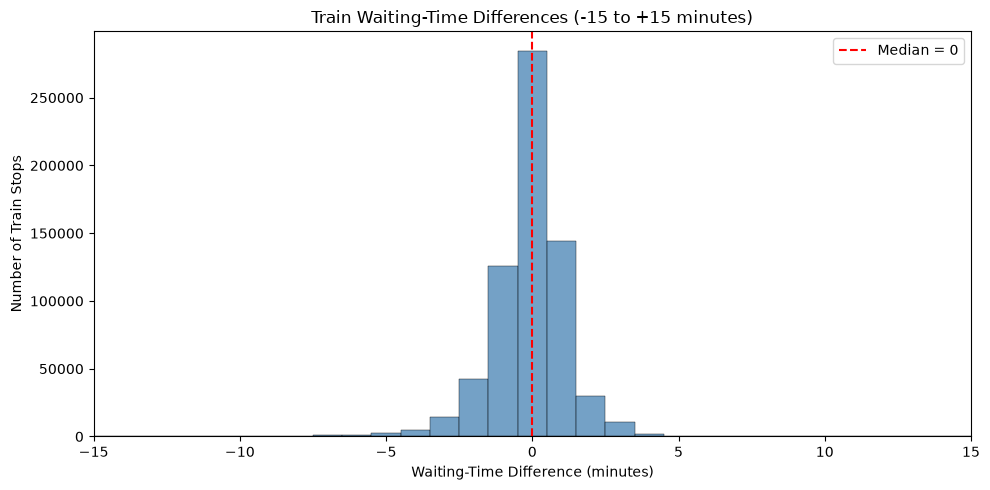

In [9]:

# Step 6: Zoom into the common waiting-time differences

target = y_clean["waiting_time_difference"]

plt.figure(figsize=(10, 5))

sns.histplot(
    target,
    discrete=True,
    color="steelblue"
)

plt.xlim(-15, 15)

plt.axvline(
    target.median(),
    color="red",
    linestyle="--",
    label=f"Median = {target.median():.0f}"
)

plt.title("Train Waiting-Time Differences (-15 to +15 minutes)")
plt.xlabel("Waiting-Time Difference (minutes)")
plt.ylabel("Number of Train Stops")
plt.legend()
plt.tight_layout()

plt.show()


In [10]:

# Step 7: Analyze normal and extreme waiting-time differences

target = y_clean["waiting_time_difference"]

print("Minimum:", target.min())
print("Maximum:", target.max())
print("Mean:", round(target.mean(), 3))
print("Median:", target.median())
print("Standard deviation:", round(target.std(), 3))

print("\nPercentage of observations:")

print("Negative:",
      round((target < 0).mean() * 100, 2), "%")

print("Exactly zero:",
      round((target == 0).mean() * 100, 2), "%")

print("Positive:",
      round((target > 0).mean() * 100, 2), "%")

print("Outside -15 to +15 minutes:",
      round((target.abs() > 15).mean() * 100, 3), "%")


Minimum: -160.0
Maximum: 15.0
Mean: -0.16
Median: 0.0
Standard deviation: 1.988

Percentage of observations:
Negative: 29.34 %
Exactly zero: 42.67 %
Positive: 27.99 %
Outside -15 to +15 minutes: 0.143 %


## Exploratory Data Analysis (EDA) — Summary So Far

### 1. Dataset Overview
- Loaded the SNCF training datasets (`x_train_final.csv` and `y_train_final_j5KGWWK.csv`).
- The dataset contains **667,264 observations**.
- The input dataset originally contained 12 columns, while the target dataset contained 2 columns.
- Each observation represents a train stopping at a particular station on a specific date.
- Our target variable is `waiting_time_difference` (originally `p0q0`).

### 2. Data Inspection and Cleaning
- Checked column names, data types, missing values, and duplicate rows.
- All input features and the target contain **no missing values**.
- Found two unnecessary index columns in X and one in Y.
- Verified that the two extra columns in X contain the row numbers.
- Removed the extra index columns, leaving **10 input features and 1 target variable**.
- Renamed the columns to more meaningful names for easier understanding.

### 3. Target Variable Analysis
- Analyzed the distribution of waiting-time differences.
- The median waiting-time difference is **0 minutes**.
- Most observations are concentrated around zero, particularly between approximately −3 and +3 minutes.
- The full histogram showed some extreme negative values, indicating unusually long waiting times.
- Created a second histogram focusing on values between −15 and +15 minutes to better understand the common observations.

### 4. Initial Findings
- Most waiting-time differences are relatively small.
- The target distribution has a longer negative tail, suggesting some unusually large waiting-time differences.
- The dataset is suitable for further exploratory analysis and regression modeling.
- Extreme values should be investigated before deciding whether to treat them as outliers.

Correlation with target:
waiting_time_difference          1.000000
second_previous_station_delay    0.277717
third_previous_station_delay     0.156384
fourth_previous_station_delay    0.085419
fourth_previous_train_delay      0.039447
third_previous_train_delay       0.025357
second_previous_train_delay     -0.052890
Name: waiting_time_difference, dtype: float64


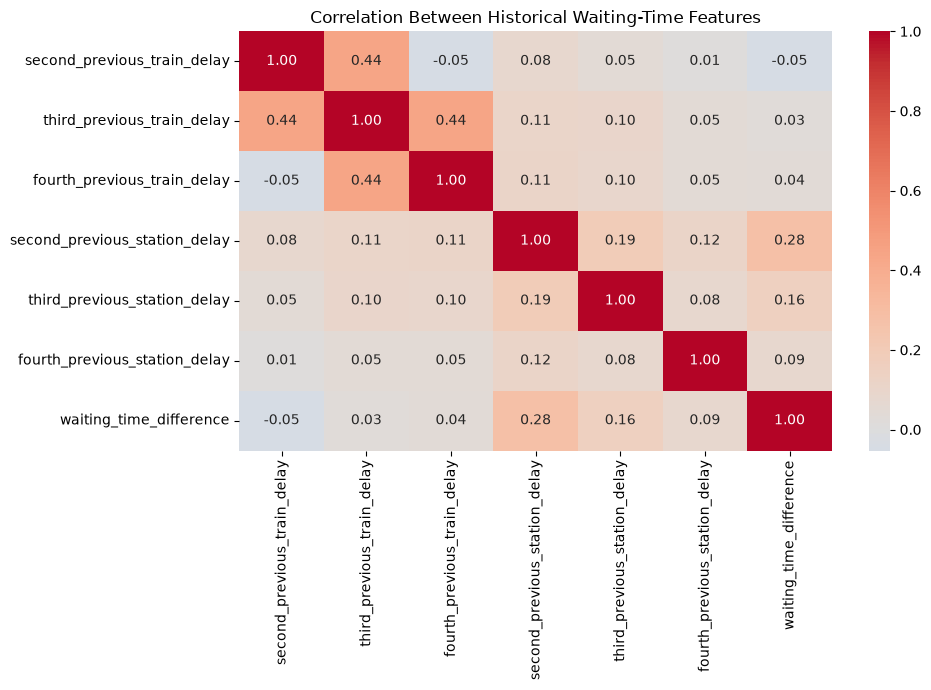

In [11]:

# Step 8: Correlation analysis

# Select the six historical waiting-time features
delay_features = [
    "second_previous_train_delay",
    "third_previous_train_delay",
    "fourth_previous_train_delay",
    "second_previous_station_delay",
    "third_previous_station_delay",
    "fourth_previous_station_delay"
]

# Combine features and target for correlation analysis
correlation_data = X_clean[delay_features].copy()
correlation_data["waiting_time_difference"] = (
    y_clean["waiting_time_difference"]
)

# Calculate Pearson correlations
corr_matrix = correlation_data.corr()

# Display correlation values with the target
print("Correlation with target:")
print(
    corr_matrix["waiting_time_difference"]
    .sort_values(ascending=False)
)

# Create correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Historical Waiting-Time Features")
plt.tight_layout()
plt.show()


### Step 8 — Correlation Analysis: Findings

We calculated Pearson correlations between the six historical waiting-time features and our target variable (`waiting_time_difference`).

**Key findings:**

- The second previous station has the highest positive correlation with the target (**r = 0.278**).
- The third previous station has a weaker positive correlation (**r = 0.156**).
- Correlations decrease for stations farther back in the journey.
- Previous-train features show very weak individual linear correlations with the target (between approximately −0.053 and 0.039).
- Some previous-train features are moderately correlated with each other (approximately 0.44).

**Conclusion:**

Waiting-time differences at earlier stations appear more informative for predicting the current waiting-time difference than observations from previous trains at the same station, based on Pearson correlation.

However, all individual correlations with the target are relatively weak. These findings do not rule out nonlinear relationships, so we will keep all six historical features for the initial machine learning experiments.

Number of unique stations: 84


,observations,mean_difference,median_difference,mean_absolute_difference
station_id,,,,
JLR,31643,0.303,0.0,0.741
KYF,29737,-0.950,-1.0,1.165
OCB,29230,-0.323,0.0,0.876
ZHN,28521,-0.616,0.0,0.931
VXY,27842,-0.530,0.0,1.110
EOH,26037,0.177,0.0,0.828
KCK,21449,-1.145,-1.0,1.161
ZFB,18559,-0.395,0.0,1.143
OJA,17175,0.145,0.0,0.515


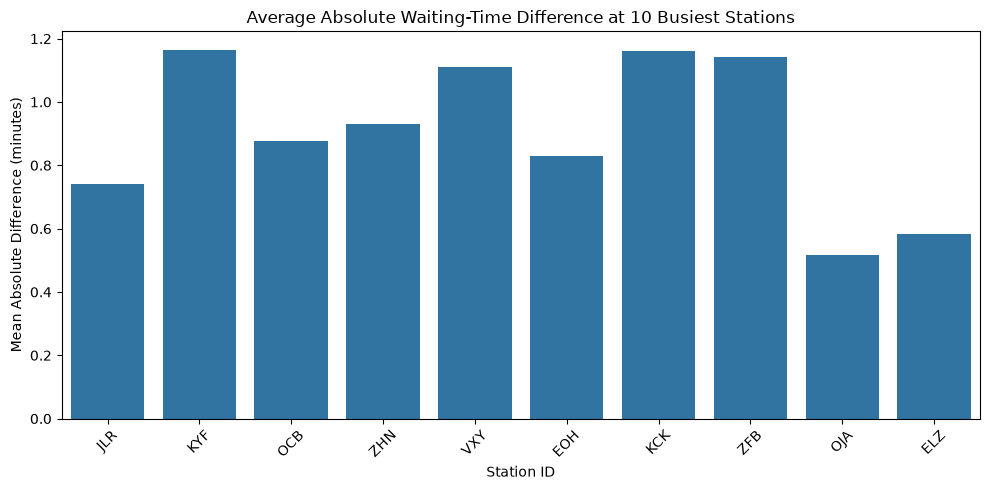

In [12]:

# Step 9: Analyze waiting-time differences by station

station_data = pd.DataFrame({
    "station_id": X_clean["station_id"],
    "waiting_time_difference": y_clean["waiting_time_difference"]
})

# Calculate statistics for each station
station_stats = station_data.groupby("station_id").agg(
    observations=("waiting_time_difference", "size"),
    mean_difference=("waiting_time_difference", "mean"),
    median_difference=("waiting_time_difference", "median"),
    mean_absolute_difference=(
        "waiting_time_difference",
        lambda x: x.abs().mean()
    )
)

print("Number of unique stations:",
      station_stats.shape[0])

# Select the 10 stations with the most observations
top_stations = station_stats.nlargest(
    10, "observations"
)

display(top_stations.round(3))

# Plot average absolute waiting-time difference
plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_stations.index,
    y=top_stations["mean_absolute_difference"]
)

plt.title("Average Absolute Waiting-Time Difference at 10 Busiest Stations")
plt.xlabel("Station ID")
plt.ylabel("Mean Absolute Difference (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Step 9 — Station-Level Analysis: Findings

We analyzed the 10 stations with the highest number of observations to investigate whether waiting-time differences vary by station.

**Key findings:**

- **KYF** has the highest mean absolute waiting-time difference (**1.165 minutes**).
- **OJA** has the lowest mean absolute difference (**0.515 minutes**).
- **KCK** has the most negative mean difference (**−1.145 minutes**), indicating that actual waiting times tend to be longer than expected.
- **JLR** and **EOH** have positive average waiting-time differences.
- The mean absolute differences vary substantially between stations, suggesting that station information may help predict waiting-time differences.

**Conclusion:**

Historical waiting-time differences vary across stations. Therefore, we will investigate whether including station identifiers improves our machine learning models.

These are descriptive findings; they do not establish that particular stations cause longer waiting times.

,observations,mean_difference,mean_absolute_difference
weekday,,,
Monday,120949.0,-0.144,0.882
Tuesday,143538.0,-0.158,0.890
Wednesday,143745.0,-0.146,0.865
Thursday,126967.0,-0.183,0.912
Friday,132065.0,-0.169,0.923
Saturday,NaN,NaN,NaN
Sunday,NaN,NaN,NaN


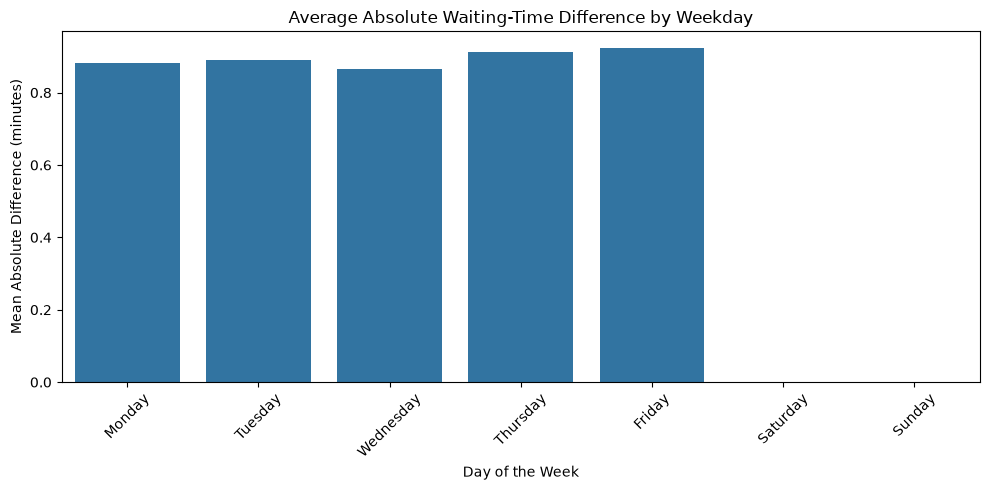

In [13]:

# Step 10: Analyze waiting-time differences by day of week

date_data = pd.DataFrame({
    "date": pd.to_datetime(X_clean["date"]),
    "waiting_time_difference": y_clean["waiting_time_difference"]
})

# Extract weekday
date_data["weekday"] = date_data["date"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Calculate average absolute difference
weekday_stats = (
    date_data.groupby("weekday")
    ["waiting_time_difference"]
    .agg(
        observations="size",
        mean_difference="mean",
        mean_absolute_difference=lambda x: x.abs().mean()
    )
    .reindex(weekday_order)
)

display(weekday_stats.round(3))

# Plot
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_stats.reset_index(),
    x="weekday",
    y="mean_absolute_difference",
    order=weekday_order
)

plt.title("Average Absolute Waiting-Time Difference by Weekday")
plt.xlabel("Day of the Week")
plt.ylabel("Mean Absolute Difference (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Waiting-time differences vary slightly across weekdays, but the differences are relatively small. We will investigate whether adding the day of the week as a feature improves our machine learning models.

,observations,mean_difference,mean_absolute_difference
stop_number,,,
7,266,-0.320,1.019
8,35571,0.010,0.801
9,35021,-0.371,0.839
10,34821,-0.221,0.830
11,34265,-0.131,0.965
12,34151,-0.281,0.823
13,33174,-0.348,0.908
14,30435,-0.285,0.848
15,31385,-0.158,0.855


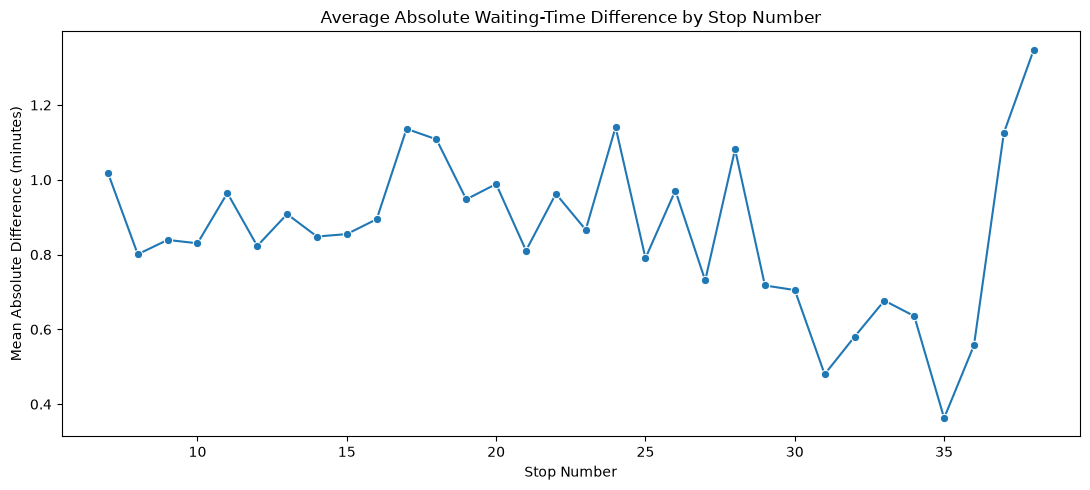

In [15]:

# Step 11: Analyze waiting-time differences by stop number

stop_data = pd.DataFrame({
    "stop_number": X_clean["stop_number"],
    "waiting_time_difference": y_clean["waiting_time_difference"]
})

# Calculate summary statistics for each stop number
stop_stats = stop_data.groupby("stop_number").agg(
    observations=("waiting_time_difference", "size"),
    mean_difference=("waiting_time_difference", "mean"),
    mean_absolute_difference=(
        "waiting_time_difference",
        lambda x: x.abs().mean()
    )
)

display(stop_stats.round(3))

# Plot stops with enough observations for stable estimates
plot_data = stop_stats[stop_stats["observations"] >= 100]

plt.figure(figsize=(11, 5))

sns.lineplot(
    x=plot_data.index,
    y=plot_data["mean_absolute_difference"],
    marker="o"
)

plt.title("Average Absolute Waiting-Time Difference by Stop Number")
plt.xlabel("Stop Number")
plt.ylabel("Mean Absolute Difference (minutes)")
plt.tight_layout()
plt.show()


### Step 11 — Stop-Number Analysis: Final Findings

We examined waiting-time differences across stop numbers 7–42.

**Key findings:**

- The average absolute waiting-time difference varies across stop numbers.
- Stop 17 has a mean absolute difference of **1.136 minutes**, while stop 35 has **0.363 minutes**.
- Stop 38 has a relatively high mean absolute difference of **1.348 minutes**, based on 3,821 observations.
- There is no consistently increasing trend as stop numbers increase.
- Stops 39–42 have very few observations, making their averages less reliable.

**Conclusion:**

Stop number may contain useful predictive information, but waiting-time differences do not consistently increase throughout the journey.

For clearer visualization, we displayed only stop numbers with at least 100 observations. All original records were retained in the dataset.

First date: 2023-04-03 00:00:00
Last date: 2023-11-10 00:00:00
Number of unique dates: 91


,observations,mean_difference,mean_absolute_difference
date,,,
2023-04-03,7951,-0.071312,0.715004
2023-04-04,7253,-0.166690,0.869847
2023-04-05,7610,-0.063338,0.697766
2023-04-06,5465,-0.088564,0.713998
2023-04-07,6192,-0.100937,0.779877


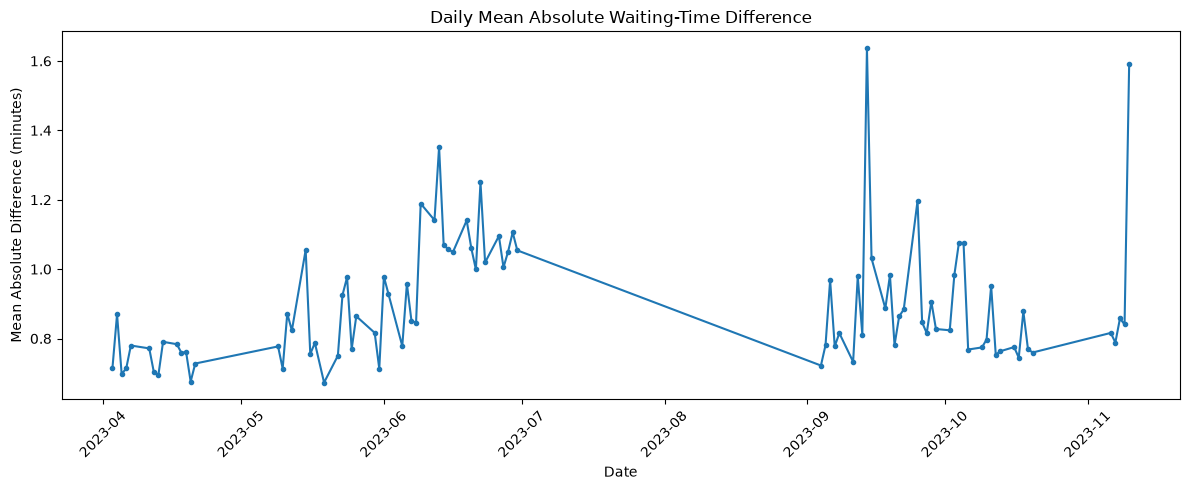

In [16]:

# Step 12: Daily waiting-time analysis

daily_data = pd.DataFrame({
    "date": pd.to_datetime(X_clean["date"]),
    "waiting_time_difference": y_clean["waiting_time_difference"]
})

daily_stats = daily_data.groupby("date").agg(
    observations=("waiting_time_difference", "size"),
    mean_difference=("waiting_time_difference", "mean"),
    mean_absolute_difference=(
        "waiting_time_difference",
        lambda x: x.abs().mean()
    )
)

print("First date:", daily_stats.index.min())
print("Last date:", daily_stats.index.max())
print("Number of unique dates:", len(daily_stats))

display(daily_stats.head())

plt.figure(figsize=(12, 5))

plt.plot(
    daily_stats.index,
    daily_stats["mean_absolute_difference"],
    marker="o",
    markersize=3
)

plt.title("Daily Mean Absolute Waiting-Time Difference")
plt.xlabel("Date")
plt.ylabel("Mean Absolute Difference (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Step 12 — Daily Waiting-Time Analysis: Findings

We analyzed the mean and mean absolute waiting-time differences for each date in the training dataset.

**Key findings:**

- The training data covers **April 3 to November 10, 2023**.
- There are observations for **91 unique dates**.
- Daily mean absolute waiting-time differences vary over time.
- April generally shows smaller discrepancies, while several dates in June and September show larger values.
- Some days have unusually high average absolute differences, exceeding approximately 1.5 minutes.
- There are gaps between observed dates, including a long gap between late June and September.

**Conclusion:**

Waiting-time differences vary across dates. This suggests that temporal factors may be relevant for prediction.

However, we cannot determine the reasons for unusually high discrepancies from this dataset alone.

The missing periods must also be considered when designing our training and validation strategy.

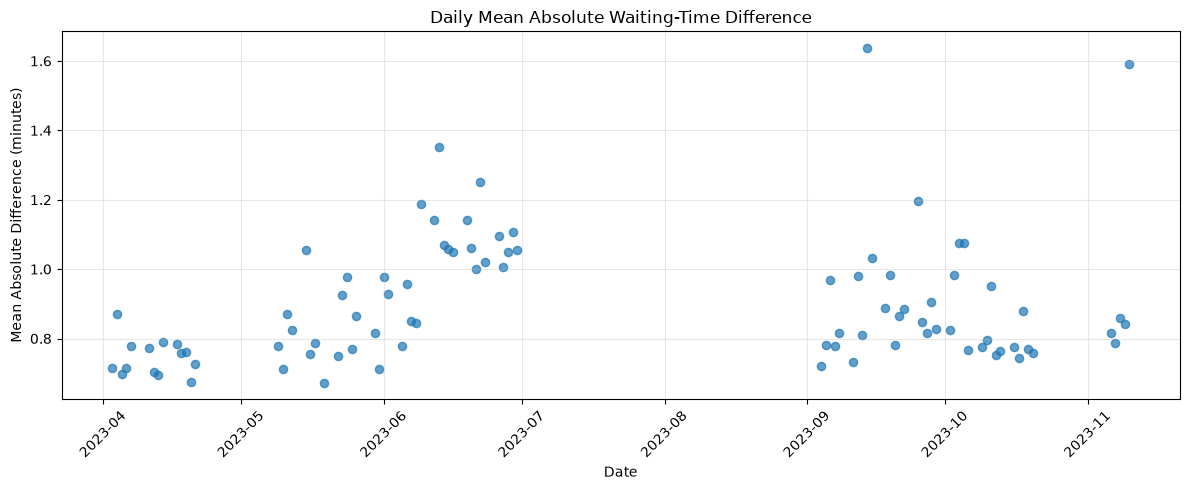

In [17]:

# Step 13: Improved daily visualization

plt.figure(figsize=(12, 5))

plt.scatter(
    daily_stats.index,
    daily_stats["mean_absolute_difference"],
    alpha=0.7,
    s=35
)

plt.title("Daily Mean Absolute Waiting-Time Difference")
plt.xlabel("Date")
plt.ylabel("Mean Absolute Difference (minutes)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Step 13 — Daily Visualization: Findings

We created a scatter plot showing the daily mean absolute waiting-time difference across the training period.

**Key findings:**
- Waiting-time differences vary across dates.
- April generally has smaller discrepancies than several dates in June.
- Some dates in September and November have unusually high average absolute differences (approximately 1.6 minutes).
- The dataset has no observations during July and August.
- Using a scatter plot avoids drawing misleading lines across missing dates.

**Conclusion:**

Date-related patterns may help explain waiting-time differences. We will investigate temporal features during model development, while ensuring that future information is not used in training.

In [18]:

# Step 14: Analyze extreme waiting-time differences

target = y_clean["waiting_time_difference"]

# Calculate percentiles
print("Target percentiles:")
print(target.quantile([0, 0.01, 0.05, 0.25, 0.5,
                       0.75, 0.95, 0.99, 1]))

# Count unusually large differences
print("\nExtreme observations:")

for threshold in [5, 10, 15, 30, 60]:
    count = (target.abs() > threshold).sum()
    percentage = count / len(target) * 100

    print(
        f"Absolute difference > {threshold} min: "
        f"{count} observations ({percentage:.3f}%)"
    )

# Examine the 10 largest absolute differences
extreme_indices = target.abs().nlargest(10).index

extreme_rows = X_clean.loc[extreme_indices].copy()
extreme_rows["waiting_time_difference"] = (
    target.loc[extreme_indices]
)

display(extreme_rows)


Target percentiles:
0.00   -160.0
0.01     -5.0
0.05     -2.0
0.25     -1.0
0.50      0.0
0.75      1.0
0.95      2.0
0.99      3.0
1.00     15.0
Name: waiting_time_difference, dtype: float64

Extreme observations:
Absolute difference > 5 min: 5247 observations (0.786%)
Absolute difference > 10 min: 1804 observations (0.270%)
Absolute difference > 15 min: 951 observations (0.143%)
Absolute difference > 30 min: 302 observations (0.045%)
Absolute difference > 60 min: 83 observations (0.012%)


,train_id,station_id,date,stop_number,second_previous_train_delay,third_previous_train_delay,fourth_previous_train_delay,second_previous_station_delay,third_previous_station_delay,fourth_previous_station_delay,waiting_time_difference
441542,IZKJSK,AZA,2023-09-14,12,1.0,-2.0,0.0,-1.0,0.0,0.0,-160.0
441559,IVPCMW,OML,2023-09-14,9,1.0,-1.0,0.0,-46.0,-48.0,-40.0,-159.0
441543,IZKJSK,ZVY,2023-09-14,13,1.0,1.0,-2.0,-1.0,-1.0,-1.0,-157.0
441560,IVPCMW,GDU,2023-09-14,10,0.0,1.0,-1.0,-40.0,1.0,0.0,-156.0
442172,LMYCHM,JBZ,2023-09-14,18,0.0,1.0,0.0,1.0,2.0,1.0,-149.0
442171,LMYCHM,ZVY,2023-09-14,17,1.0,0.0,-1.0,-1.0,-1.0,-1.0,-148.0
441764,RPTKBH,ZHN,2023-09-14,11,-2.0,0.0,0.0,-5.0,-80.0,0.0,-131.0
326179,OCNCVH,ZFB,2023-06-22,10,-1.0,0.0,1.0,1.0,3.0,0.0,-126.0
441763,RPTKBH,ELZ,2023-09-14,10,0.0,0.0,0.0,0.0,0.0,-1.0,-125.0
442445,ILZNXD,ZHN,2023-09-14,10,0.0,0.0,-1.0,-80.0,0.0,0.0,-121.0


### Step 14 — Outlier Analysis: Findings

#### Historical Patterns in Extreme Observations

We examined the 10 observations with the largest absolute waiting-time differences.

**Key findings:**

- All ten target values are highly negative, ranging from **−121 to −160 minutes**.
- Some extreme observations also have large negative historical waiting-time differences at previous stations.
- For example, an observation with a target of **−159 minutes** has previous-station differences of **−46, −48, and −40 minutes**.
- However, several extreme observations have historical values close to zero.
- This suggests that some extreme waiting-time differences may be difficult to predict using the available historical information alone.

**Implications for modeling:**

Extreme observations may produce large prediction errors, especially when previous train and station information does not indicate unusual conditions.

We will retain these observations and later compare model performance on normal and extreme cases.

**Conclusion:**

The ten most extreme observations show different historical patterns. Some contain early indications of unusually long waiting times, while others do not. Further analysis is needed before determining whether these are genuine operational events or data-quality problems.

In [20]:

# Step 14.1: Examine the trains associated
# with the 10 largest absolute differences

extreme_indices = target.abs().nlargest(10).index

extreme_trains = X_clean.loc[
    extreme_indices,
    ["train_id", "station_id", "date", "stop_number"]
].copy()

extreme_trains["waiting_time_difference"] = (
    target.loc[extreme_indices]
)

display(extreme_trains)

print("\nNumber of unique trains:",
      extreme_trains["train_id"].nunique())

print("\nExtreme observations per train:")
print(extreme_trains["train_id"].value_counts())


,train_id,station_id,date,stop_number,waiting_time_difference
441542,IZKJSK,AZA,2023-09-14,12,-160.0
441559,IVPCMW,OML,2023-09-14,9,-159.0
441543,IZKJSK,ZVY,2023-09-14,13,-157.0
441560,IVPCMW,GDU,2023-09-14,10,-156.0
442172,LMYCHM,JBZ,2023-09-14,18,-149.0
442171,LMYCHM,ZVY,2023-09-14,17,-148.0
441764,RPTKBH,ZHN,2023-09-14,11,-131.0
326179,OCNCVH,ZFB,2023-06-22,10,-126.0
441763,RPTKBH,ELZ,2023-09-14,10,-125.0
442445,ILZNXD,ZHN,2023-09-14,10,-121.0



Number of unique trains: 6

Extreme observations per train:
train_id
IZKJSK    2
IVPCMW    2
LMYCHM    2
RPTKBH    2
OCNCVH    1
ILZNXD    1
Name: count, dtype: int64


### Step 14.1 — Extreme Observations by Train

We examined the 10 largest absolute waiting-time differences and identified the trains associated with them.

**Key findings:**

- The 10 extreme observations belong to **6 distinct train identifiers**.
- Four trains appear twice among these observations.
- Some consecutive stops of the same train have similarly large negative differences.
- For example, train IZKJSK on September 14 has waiting-time differences of −160 and −157 minutes at stops 12 and 13.

**Conclusion:**

Some extreme waiting-time differences occur across multiple stops of the same train journey rather than as isolated observations.

This suggests that train-level patterns may help explain certain extreme cases. However, further analysis is needed to understand how frequently such patterns occur.

In [19]:

# Step 15: Investigate extreme values by date

outlier_data = pd.DataFrame({
    "date": pd.to_datetime(X_clean["date"]),
    "waiting_time_difference": y_clean["waiting_time_difference"]
})

# Flag absolute differences greater than 15 minutes
outlier_data["is_extreme"] = (
    outlier_data["waiting_time_difference"].abs() > 15
)

# Calculate daily statistics
daily_outliers = outlier_data.groupby("date").agg(
    observations=("waiting_time_difference", "size"),
    extreme_count=("is_extreme", "sum"),
    mean_absolute_difference=(
        "waiting_time_difference",
        lambda x: x.abs().mean()
    )
)

# Percentage of extreme observations each day
daily_outliers["extreme_percentage"] = (
    daily_outliers["extreme_count"]
    / daily_outliers["observations"] * 100
)

# Show the 10 dates with the most extreme values
display(
    daily_outliers.sort_values(
        "extreme_count", ascending=False
    ).head(10).round(3)
)

# Examine September 14 directly
print("\nSeptember 14, 2023:")
display(daily_outliers.loc["2023-09-14"].round(3))


,observations,extreme_count,mean_absolute_difference,extreme_percentage
date,,,,
2023-11-10,7026,74,1.592,1.053
2023-09-25,7058,57,1.197,0.808
2023-09-14,5597,53,1.637,0.947
2023-09-15,7005,47,1.031,0.671
2023-10-11,8073,44,0.952,0.545
2023-10-04,7720,40,1.077,0.518
2023-09-19,7782,27,0.982,0.347
2023-06-01,8105,26,0.978,0.321
2023-09-28,7833,24,0.906,0.306



September 14, 2023:


observations                5597.000
extreme_count                 53.000
mean_absolute_difference       1.637
extreme_percentage             0.947
Name: 2023-09-14 00:00:00, dtype: float64

Daily observation statistics:
count      91.000000
mean     7332.571429
std      1125.083643
min      2222.000000
25%      7122.500000
50%      7743.000000
75%      8046.000000
max      8417.000000
Name: observations, dtype: float64

Five dates with the most observations:


,observations,mean_difference,mean_absolute_difference
date,,,
2023-05-16,8417,-0.098610,0.755614
2023-05-10,8376,-0.112822,0.713348
2023-04-17,8368,-0.101816,0.783700
2023-06-21,8361,-0.114699,0.999043
2023-05-22,8331,-0.084144,0.750570



Five dates with the fewest observations:


,observations,mean_difference,mean_absolute_difference
date,,,
2023-10-05,2222,-0.294779,1.075158
2023-09-26,3137,-0.189034,0.846350
2023-06-05,4312,-0.129870,0.778293
2023-05-19,4983,0.089504,0.673089
2023-10-20,5213,-0.082102,0.759639


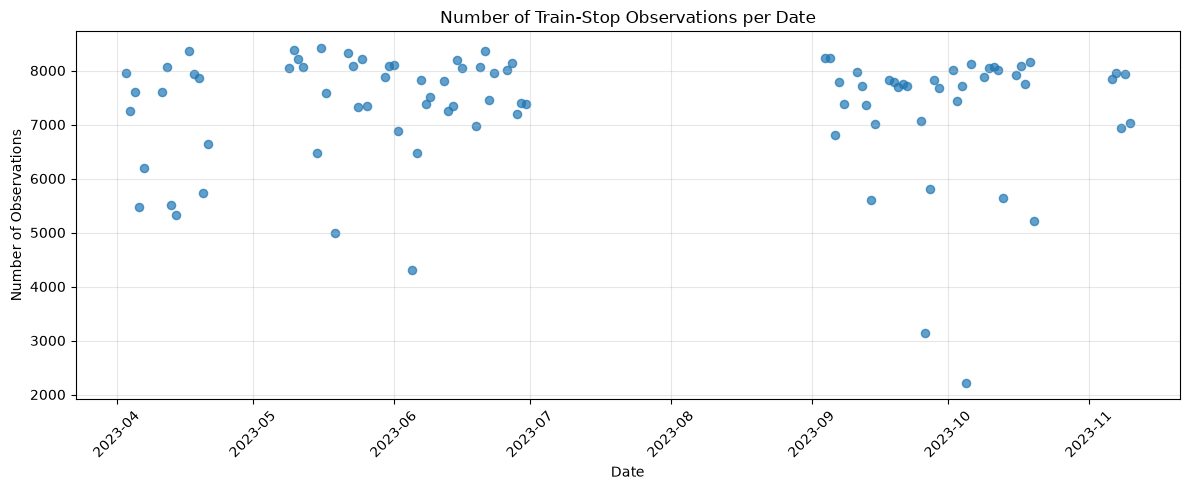

In [21]:

# Step 16: Check daily observation counts

print("Daily observation statistics:")
print(daily_stats["observations"].describe())

print("\nFive dates with the most observations:")
display(
    daily_stats.nlargest(5, "observations")
)

print("\nFive dates with the fewest observations:")
display(
    daily_stats.nsmallest(5, "observations")
)

# Plot the number of observations per date
plt.figure(figsize=(12, 5))

plt.scatter(
    daily_stats.index,
    daily_stats["observations"],
    alpha=0.7,
    s=35
)

plt.title("Number of Train-Stop Observations per Date")
plt.xlabel("Date")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Step 16 — Daily Observation Counts: Findings

We investigated how many train-stop observations are available for each date.

**Key findings:**

- The dataset contains **91 unique dates**.
- The average number of observations per date is approximately **7,333**.
- The median is **7,743 observations per date**.
- The maximum is **8,417 observations** on May 16, 2023.
- The minimum is **2,222 observations** on October 5, 2023.
- Most dates contain approximately 7,000–8,000 observations, but some dates have considerably fewer records.
- There are gaps in the date coverage, including July and August.

**Conclusion:**

The number of observations varies between dates. Therefore, dates with fewer records may require more careful interpretation.

These differences should also be considered when evaluating our models and selecting training and validation periods.

In [22]:

# Step 17: Check duplicates using actual train-stop identifiers

key_columns = [
    "train_id",
    "station_id",
    "date",
    "stop_number"
]

duplicate_count = X_clean.duplicated(
    subset=key_columns
).sum()

print("Duplicate train-stop identifiers:", duplicate_count)

# Show examples if duplicates exist
if duplicate_count > 0:
    duplicate_rows = X_clean[
        X_clean.duplicated(
            subset=key_columns,
            keep=False
        )
    ]

    display(
        duplicate_rows.sort_values(
            key_columns
        ).head(10)
    )


Duplicate train-stop identifiers: 0
